In [1]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt

In [2]:

expression = "x**2 - 8*cos(2*pi*x) + 8"

a = -5.12
b = 5.12
eps = 0.01

def make_function(expression):
    code = compile(expression, "<function>", "eval")

    def func(x):
        allowed = {
            "x": float(x),
            "sin": math.sin,
            "cos": math.cos,
            "tan": math.tan,
            "exp": math.exp,
            "sqrt": math.sqrt,
            "log": math.log,
            "abs": abs,
            "pi": math.pi,
            "e": math.e
        }

        try:
            y = float(eval(code, {"__builtins__": {}}, allowed))
        except Exception as error:
            raise ValueError(
                f"Ошибка вычисления функции при x={x}: {error}"
            ) from error

        if not math.isfinite(y):
            raise ValueError(
                f"Функция вернула NaN или Inf при x={x}"
            )

        return y

    return func

f = make_function(expression)

print("Функция: ", expression)
print("Отрезок: ", a, b)
print("Точность: ", eps)


Функция:  x**2 - 8*cos(2*pi*x) + 8
Отрезок:  -5.12 5.12
Точность:  0.01


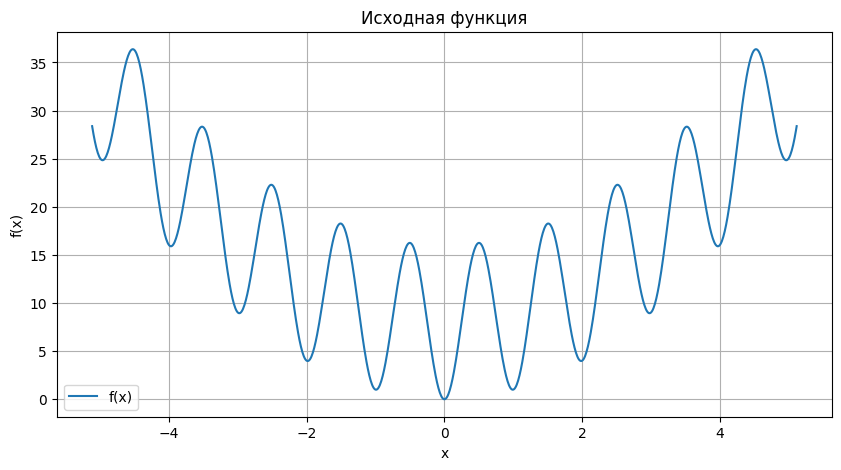

In [3]:
x_values = np.linspace(a, b, 1000)
y_values = [f(x) for x in x_values]

plt.figure(figsize=(10, 5))
plt.plot(x_values, y_values, label="f(x)")
plt.title("Исходная функция")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.show()

In [4]:

def estimate_lipschitz(f, a, b, levels=6, initial_intervals=32,
                       safety_factor=1.2):
    if not a < b:
        raise ValueError("Левая граница должна быть меньше правой")
    if levels < 1 or initial_intervals < 1:
        raise ValueError("Некорректные параметры сетки")
    if safety_factor <= 1:
        raise ValueError("Коэффициент запаса должен быть больше 1")

    max_slope = 0.0
    evaluations = 0
    grid_history = []

    cache = {}

    def evaluate(x):
        nonlocal evaluations
        x = float(x)

        if x not in cache:
            cache[x] = f(x)
            evaluations += 1

        return cache[x]

    for level in range(levels):
        n = initial_intervals * (2 ** level)
        xs = np.linspace(a, b, n + 1)
        ys = np.array([evaluate(x) for x in xs])

        slopes = np.abs(np.diff(ys) / np.diff(xs))
        current_max = float(np.max(slopes))

        max_slope = max(max_slope, current_max)
        grid_history.append((n, current_max))

    L = max(safety_factor * max_slope, 1e-8)

    return L, evaluations, grid_history


L, grid_evaluations, grid_history = estimate_lipschitz(f, a, b)

print("Оценка L: " , round(L, 6))
print("Вычислений функции на сетках: ", grid_evaluations)

for n, slope in grid_history:
    print(f"Интервалов: {n:5d}, максимальный наклон: {slope:.6f}")


Оценка L:  70.490899
Вычислений функции на сетках:  1025
Интервалов:    32, максимальный наклон: 46.838537
Интервалов:    64, максимальный наклон: 56.560304
Интервалов:   128, максимальный наклон: 57.416981
Интервалов:   256, максимальный наклон: 58.554367
Интервалов:   512, максимальный наклон: 58.732416
Интервалов:  1024, максимальный наклон: 58.742416


In [5]:

def broken_line_method(f, a, b, eps, L,
                       max_iter=10000, safety_factor=1.2):

    if not (math.isfinite(a) and math.isfinite(b)
            and math.isfinite(eps) and math.isfinite(L)):
        raise ValueError("Параметры должны быть конечными числами ")

    if a >= b or eps <= 0 or L <= 0 or max_iter < 1:
        raise ValueError("Некорректные параметры метода ")

    start = time.perf_counter()
    evaluations = 0
    L_updates = 0

    def evaluate(x):
        nonlocal evaluations
        y = float(f(x))
        evaluations += 1

        if not math.isfinite(y):
            raise ValueError(f"NaN или Inf при x={x}")

        return y

    points = [(a, evaluate(a)), (b, evaluate(b))]
    point_order = points.copy()
    history = []

    converged = False
    stop_reason = "Достигнут предел итераций"

    for step in range(max_iter):
        points.sort(key=lambda p: p[0])
        slopes = [
            abs((points[i + 1][1] - points[i][1]) /
                (points[i + 1][0] - points[i][0]))
            for i in range(len(points) - 1)
        ]

        max_slope = max(slopes)

        if max_slope > L:
            L = safety_factor * max_slope
            L_updates += 1

        candidates = []

        for i in range(len(points) - 1):
            x1, y1 = points[i]
            x2, y2 = points[i + 1]

            x_new = (x1 + x2) / 2 + (y1 - y2) / (2 * L)
            lower = (y1 + y2 - L * (x2 - x1)) / 2

            if not (math.isfinite(x_new)
                    and math.isfinite(lower)):
                raise ValueError("Некорректная нижняя оценка")

            candidates.append((lower, x_new))

        lower, x_new = min(candidates)
        best_x, best_y = min(points, key=lambda p: p[1])
        gap = best_y - lower

        tolerance = 1e-10 * max(
            1.0, abs(best_y), abs(lower)
        )

        if gap < -tolerance:
            raise RuntimeError(
                "Отрицательный разрыв: нижняя оценка выше "
                "лучшего значения функции. Проверьте L."
            )

        history.append((step + 1, best_y, lower, gap))

        if gap <= eps and gap >= -tolerance:
            converged = True
            stop_reason = "Достигнута заданная точность"
            break

        if any(abs(x_new - x) < 1e-12 for x, _ in points):
            stop_reason = "Новая точка совпала с существующей"
            break

        y_new = evaluate(x_new)
        new_point = (x_new, y_new)

        points.append(new_point)
        point_order.append(new_point)

    points.sort(key=lambda p: p[0])
    best_x, best_y = min(points, key=lambda p: p[1])

    return {
        "x_min": best_x,
        "f_min": best_y,
        "points": points,
        "point_order": point_order,
        "history": history,
        "elapsed": time.perf_counter() - start,
        "converged": converged,
        "stop_reason": stop_reason,
        "L": L,
        "L_updates": L_updates,
        "evaluations": evaluations,
        "iterations": len(history)
    }


def solve(expression, a, b, eps, max_iter=10000):
    """Единый интерфейс для запуска метода по строке функции"""

    func = make_function(expression)

    L_initial, grid_count, grid_history = estimate_lipschitz(
        func, a, b
    )

    result = broken_line_method(
        func, a, b, eps, L_initial, max_iter
    )

    result["L_initial"] = L_initial
    result["grid_evaluations"] = grid_count
    result["grid_history"] = grid_history
    result["total_evaluations"] = (
        grid_count + result["evaluations"]
    )

    return result


In [6]:

result = solve(expression, a, b, eps)

x_min = result["x_min"]
y_min = result["f_min"]
points = result["points"]
point_order = result["point_order"]
history = result["history"]
elapsed = result["elapsed"]
converged = result["converged"]
stop_reason = result["stop_reason"]

L = result["L"]

print("Начальная оценка L: ", round(result["L_initial"], 6))
print("Итоговая оценка L: ", round(L, 6))
print("Количество увеличений L: ", result["L_updates"])

print("Найденная точка: " , round(x_min, 6))
print("Значение функции: ", round(y_min, 6))
print("Количество итераций: ", result["iterations"])
print("Количество пробных точек: ", len(points))
print("Вычислений функции в методе: ", result["evaluations"])
print("Всего вычислений с учётом сеток: ",
      result["total_evaluations"])

print("Время работы:", round(elapsed, 5), "сек")
print("Достигнутая точность:", round(history[-1][3], 6))
print("Причина остановки:", stop_reason)

if converged:
    print("Метод успешно завершился ")
else:
    print("Заданная точность не достигнута ")


Начальная оценка L:  70.490899
Итоговая оценка L:  70.490899
Количество увеличений L:  0
Найденная точка:  0.0
Значение функции:  0.0
Количество итераций:  176
Количество пробных точек:  177
Вычислений функции в методе:  177
Всего вычислений с учётом сеток:  1202
Время работы: 0.05267 сек
Достигнутая точность: 0.009756
Причина остановки: Достигнута заданная точность
Метод успешно завершился 


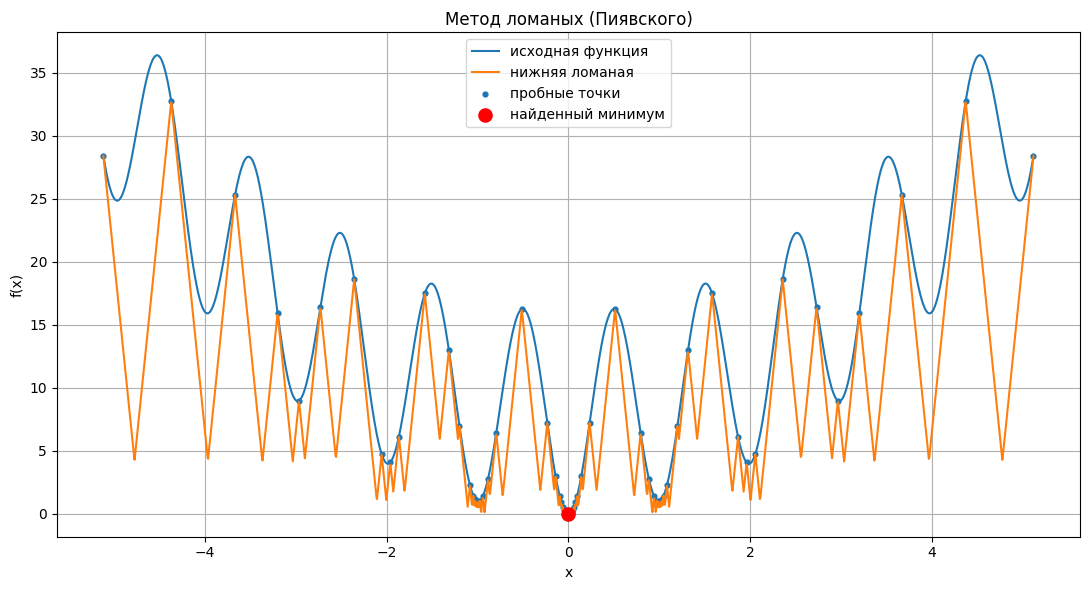

In [7]:
def get_lower_line(xs, points, L):
    line = np.full(len(xs), -np.inf)

    for x, y in points:
        current = y - L * np.abs(xs - x)
        line = np.maximum(line, current)

    return line


xs = np.linspace(a, b, 2000)
ys = np.array([f(x) for x in xs])
lower_line = get_lower_line(xs, points, L)

plt.figure(figsize=(11, 6))

plt.plot(xs, ys, label="исходная функция")
plt.plot(xs, lower_line, label="нижняя ломаная")

px = [p[0] for p in points]
py = [p[1] for p in points]

plt.scatter(px, py, s=12, label="пробные точки")
plt.scatter(x_min, y_min, color="red", s=90,
            label="найденный минимум", zorder=5)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Метод ломаных (Пиявского)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("result.png", dpi=200)
plt.show()

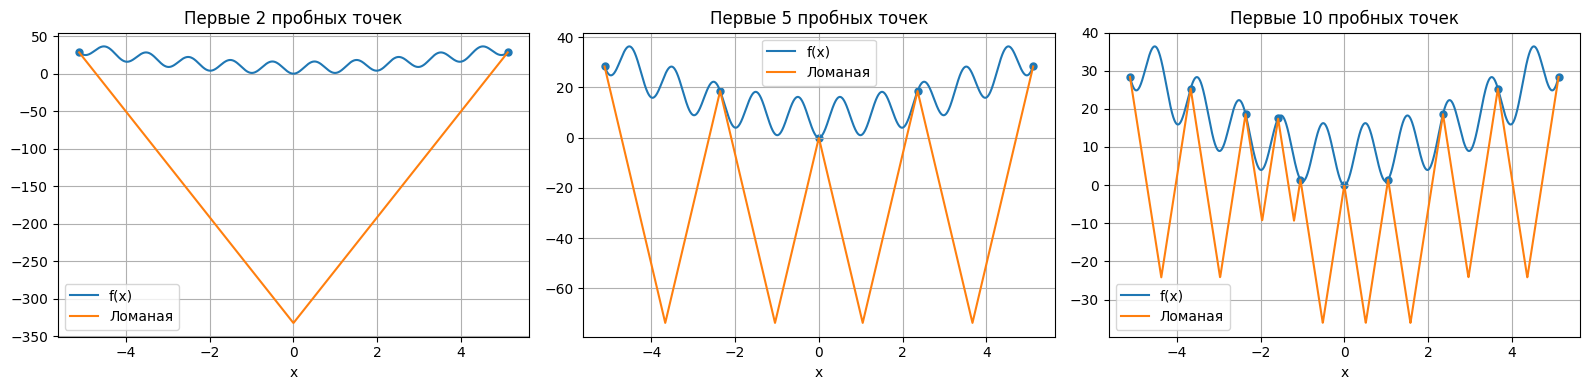

In [8]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, count in zip(axes, [2, 5, 10]):
    current_points = point_order[:count]
    current_line = get_lower_line(xs, current_points, L)

    ax.plot(xs, ys, label="f(x)")
    ax.plot(xs, current_line, label="Ломаная")

    ax.scatter(
        [p[0] for p in current_points],
        [p[1] for p in current_points],
        s=25
    )

    ax.set_title(f"Первые {count} пробных точек")
    ax.set_xlabel("x")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.savefig("steps.png", dpi=200)
plt.show()


In [9]:

print("Проверка результата для основной функции")

exact_x = 0
exact_y = f(exact_x)

print("Найденный x:", x_min)
print("Найденное W(x):", y_min)

print("Точный минимум x =", exact_x)
print("Точное значение W(0) =", exact_y)

print("Ошибка по аргументу:", abs(x_min - exact_x))
print("Ошибка по функции:", abs(y_min - exact_y))

if converged:
    print("Критерий остановки выполнен")
else:
    print("Критерий остановки не достигнут")


Проверка результата для основной функции
Найденный x: 0.0
Найденное W(x): 0.0
Точный минимум x = 0
Точное значение W(0) = 0.0
Ошибка по аргументу: 0.0
Ошибка по функции: 0.0
Критерий остановки выполнен


In [10]:
# проверка на второй функции (тест)

expression2 = "(x - 1)**2 + sin(x - 1)**2"

a2 = -2
b2 = 4
eps2 = 0.01

result2 = solve(expression2, a2, b2, eps2)

print("Проверка на второй функции")
print("Оценка L:", round(result2["L"], 6))
print("Найденная точка:", round(result2["x_min"], 6))
print("Значение функции:", round(result2["f_min"], 6))
print("Количество итераций:", result2["iterations"])
print("Достигнутая точность:",
      round(result2["history"][-1][3], 6))
print("Количество вычислений функции:",
      result2["total_evaluations"])
print("Количество увеличений L:",
      result2["L_updates"])

if not result2["converged"]:
    print("Предупреждение: заданная точность не достигнута")


Проверка на второй функции
Оценка L: 6.850927
Найденная точка: 1.0
Значение функции: 0.0
Количество итераций: 108
Достигнутая точность: 0.008968
Количество вычислений функции: 1134
Количество увеличений L: 0
